# 02 · Conditional Edges & Loops  🟢 Beginner

Real apps branch ("if the answer is bad, retry") and loop ("keep calling tools until done").
LangGraph supports **cycles**, which is what makes agents possible.

## 1. Branching with a router function

A *router* reads state and returns the **name of the next node**.
`Literal[...]` type hints let LangGraph draw the possible branches.

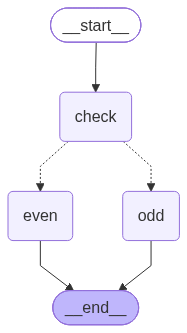

In [1]:
from typing import TypedDict, Literal
from langgraph.graph import StateGraph, START, END
from helpers import show_graph

class NumState(TypedDict):
    number: int
    message: str

def check(state: NumState):
    return {}                      # a node may change nothing

def even(state: NumState):
    return {"message": f"{state['number']} is even ✅"}

def odd(state: NumState):
    return {"message": f"{state['number']} is odd 🔸"}

def route(state: NumState) -> Literal["even", "odd"]:
    return "even" if state["number"] % 2 == 0 else "odd"

b = StateGraph(NumState)
b.add_node(check); b.add_node(even); b.add_node(odd)
b.add_edge(START, "check")
b.add_conditional_edges("check", route)       # router decides
b.add_edge("even", END); b.add_edge("odd", END)
branch_graph = b.compile()
show_graph(branch_graph)

In [2]:
for n in [4, 7]:
    print(branch_graph.invoke({"number": n})["message"])

4 is even ✅
7 is odd 🔸


You can also give a **mapping** from router return values to node names
(useful when the router returns labels like `"yes"` / `"no"`):

```python
builder.add_conditional_edges("check", router_fn, {"yes": "even", "no": "odd"})
```

## 2. Loops: retry until a condition holds

Simulated "quality check" loop: a writer improves a draft until its score ≥ 8 or it gives up after 5 tries.

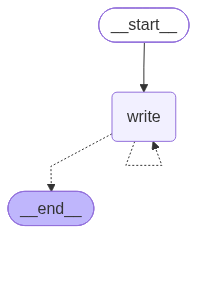

attempt 1: score 6
attempt 2: score 8


{'draft': 'draft v2', 'score': 8, 'attempts': 2}

In [3]:
import random

class DraftState(TypedDict):
    draft: str
    score: int
    attempts: int

def write(state: DraftState):
    attempts = state.get("attempts", 0) + 1
    score = min(10, random.randint(3, 6) + attempts)    # gets better each try
    print(f"attempt {attempts}: score {score}")
    return {"draft": f"draft v{attempts}", "score": score, "attempts": attempts}

def good_enough(state: DraftState) -> Literal["write", "__end__"]:
    if state["score"] >= 8 or state["attempts"] >= 5:
        return END
    return "write"                                      # 🔁 loop back

b = StateGraph(DraftState)
b.add_node(write)
b.add_edge(START, "write")
b.add_conditional_edges("write", good_enough)
loop_graph = b.compile()
show_graph(loop_graph)
random.seed(1)
loop_graph.invoke({"attempts": 0})

## 3. Safety net: `recursion_limit`

A buggy loop could run forever. Every run has a step limit (default 25 super-steps).

In [4]:
from langgraph.errors import GraphRecursionError

b = StateGraph(DraftState)
b.add_node("forever", lambda s: {"attempts": s["attempts"] + 1})
b.add_edge(START, "forever")
b.add_edge("forever", "forever")       # infinite loop!
bad = b.compile()

try:
    bad.invoke({"attempts": 0}, config={"recursion_limit": 10})
except GraphRecursionError as e:
    print("Stopped:", type(e).__name__)

Stopped: GraphRecursionError


## 4. `Command`: update state AND choose the next node in one return

Instead of a separate router, a node can return `Command(update=..., goto=...)`.
The return type `Command[Literal[...]]` tells LangGraph the possible destinations (for drawing/validation).

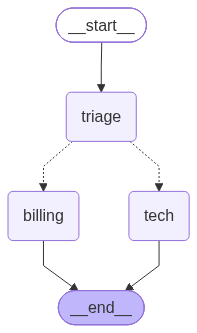

{'text': '💳 Billing team will reply: I want a refund for a double charge', 'queue': 'billing'}
{'text': '🛠️ Tech team will reply: App crashes on login', 'queue': 'tech'}


In [5]:
from langgraph.types import Command

class TicketState(TypedDict):
    text: str
    queue: str

def triage(state: TicketState) -> Command[Literal["billing", "tech"]]:
    is_billing = any(w in state["text"].lower() for w in ["refund", "invoice", "charge"])
    target = "billing" if is_billing else "tech"
    return Command(update={"queue": target}, goto=target)

def billing(state: TicketState):
    return {"text": "💳 Billing team will reply: " + state["text"]}

def tech(state: TicketState):
    return {"text": "🛠️ Tech team will reply: " + state["text"]}

b = StateGraph(TicketState)
b.add_node(triage); b.add_node(billing); b.add_node(tech)
b.add_edge(START, "triage"); b.add_edge("billing", END); b.add_edge("tech", END)
cmd_graph = b.compile()
show_graph(cmd_graph)
print(cmd_graph.invoke({"text": "I want a refund for a double charge"}))
print(cmd_graph.invoke({"text": "App crashes on login"}))

## ✅ Recap
* `add_conditional_edges(node, router)` → branching; routers return node names (or `END`).
* Edges can point **backwards** → loops. Protect with `recursion_limit`.
* `Command(update=..., goto=...)` combines state update + routing inside a node.

Next: replace our fake logic with a real LLM.